## Сегментация изображений клеток

Вам предстоит обучить модель сегментировать изображения с дрожжевыми клетками и микроструктурами (см. [segmentation.ipynb](../notebooks/segmentation.ipynb)), по пути поэкспериментировав с разными архитектурами и функцими ошибки.

### Задание 1 (2 балл). Метрики сегментации
Перед экспериментами нужно определиться с метриками. Выберите 3-5 метрик, по которым вы будете оценивать качество модели. В этом задании объясните свой выбор и найдите нужные метрики в `torchmetrics` (а если их нет - реализуйте самостоятельно, здесь вам может помочь [lightning_etc.ipynb](../notebooks/lightning_etc.ipynb))

##### 1. Intersection over Union (IoU)
Измеряет долю пересечения предсказанной и истинной областей класса к их объединенной площади. Данная метрика устойчива к дисбалансу классов, реагирует и на пропущенные, и на лишние пиксели.
(в torchmetrics: from torchmetrics.classification import MulticlassJaccardIndex)

##### 2. F1
измеряет, насколько хорошо предсказанная маска совпадает с истинной (как и IoU), но более чувствительна к маленьким объектам, при этом IoU - более строгая метрика: показывает меньшее значение при равных небольших расхождениях
(в torchmetrics: from torchmetrics.classification import MulticlassF1Score)

##### 3. Precision и Precall
Precision измеряет насколько предсказанные области действительно содержат клетки. Precall - насколько хорошо модель находит все клетки. Благодаря этим метрикам можно будет проверять, где модель больше ошибается - находит клетки там, где их на самом деле нет, либо не находит существующие клетки. Несмотря на то, что уже используем F1, эти метрики все равно будут полезны, т.к F1 дает понять, насколько в общем модель хороша, а recall и precision могут показать на конкретные ее слабые места
(в torchmetrics: from torchmetrics.classification import MulticlassPrecision, MulticlassRecall)

### Задание 2 (4 балла). Обучение модели
Возьмите модель и датасеты из практики по сегментации и запустите обучение.

Указания:
- Каждую эпоху сохраняйте значения ошибки и выбранные в задании 1 метрики как для обучающего датасета (`train`), так и для валидационного (`val`).
- Каждую эпоху сохраняйте примеры работы модели на 8 случайных изображениях из валидационного датасета (одной картинкой, как в практике).
- После окончания обучения выведите графики значений ваших метрик и примеры предсказаний (достаточно 4-5 изображений: для первой эпохи, 2-3 в середине обучения и для последней эпохи).
- Можете использовать `lightning` (вместо `lightning.pytorch.loggers.TensorBoardLogger` можно использовать `lightning.pytorch.loggers.CSVLogger`, а сохранение изображений можете реализовать как `lightning.pytorch.Callback`), а можете всё написать вручную.

In [153]:
from pathlib import Path

import pytorch_lightning as L
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch import Tensor
from torch.utils.data import Dataset
from torchvision import transforms
import torchmetrics
from typing import Any

from torchmetrics.classification import MulticlassPrecision, MulticlassRecall, MulticlassJaccardIndex, MulticlassF1Score, MulticlassAccuracy
from pytorch_lightning.utilities.types import EVAL_DATALOADERS, TRAIN_DATALOADERS, STEP_OUTPUT

from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping
from pytorch_lightning.loggers import CSVLogger
from pytorch_lightning.loggers import TensorBoardLogger
from torch.utils.data import DataLoader
from pytorch_lightning import Trainer

torch.manual_seed(42)
L.seed_everything(42)

Seed set to 42


42

In [154]:
#! wget https://tudatalib.ulb.tu-darmstadt.de/bitstream/handle/tudatalib/3799/yeast_cell_in_microstructures_dataset.zip
#! unzip yeast_cell_in_microstructures_dataset.zip -d yeast_cell_in_microstructures_dataset

In [155]:
def create_metrics(num_classes: int, prefix: str) -> torchmetrics.MetricCollection:
    return torchmetrics.MetricCollection(
        [
            MulticlassJaccardIndex(num_classes=num_classes, average="macro"),
            MulticlassF1Score(num_classes=num_classes, average="macro"),
            MulticlassPrecision(num_classes=num_classes, average="macro"),
            MulticlassRecall(num_classes=num_classes, average="macro"),
        ],
        prefix=prefix,
    )

In [156]:
class DoubleConv(nn.Module):
    def __init__(
        self, in_channels: int, out_channels: int, mid_channels: int | None = None
    ) -> None:
        super().__init__()
        if not mid_channels:
            mid_channels = out_channels
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, mid_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(mid_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(mid_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x: Tensor) -> Tensor:
        return self.double_conv(x)

In [157]:
class Down(nn.Module):
    def __init__(self, in_channels: int, out_channels: int) -> None:
        super().__init__()
        self.maxpool_conv = nn.Sequential(
            nn.MaxPool2d(2), DoubleConv(in_channels, out_channels)
        )

    def forward(self, x: Tensor) -> Tensor:
        return self.maxpool_conv(x)

In [158]:
def create_downscaler(channel_sizes: list[int], bilinear: bool = False) -> nn.ModuleList:
    modules = []
    for i in range(len(channel_sizes) - 1):
        in_channels = channel_sizes[i]
        out_channels = channel_sizes[i + 1]
        is_last_module = i == len(channel_sizes) - 2
        dfactor = 2 if bilinear and is_last_module else 1
        modules.append(Down(in_channels, out_channels // dfactor))

    return nn.ModuleList(modules)

In [159]:
class Up(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, bilinear: bool = True) -> None:
        super().__init__()

        if bilinear:
            self.up = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=True)
            self.conv = DoubleConv(in_channels, out_channels, in_channels // 2)
        else:
            self.up = nn.ConvTranspose2d(in_channels, in_channels // 2, kernel_size=2, stride=2)
            self.conv = DoubleConv(in_channels, out_channels)

    def forward(self, x_prev: Tensor, x_skip: Tensor) -> Tensor:
        x_prev = self.up(x_prev)
        x = torch.cat([x_skip, x_prev], dim=1)
        return self.conv(x)

In [160]:
def create_upscaler(channel_sizes: list[int], bilinear: bool = False) -> nn.ModuleList:
    modules = []
    for i in range(len(channel_sizes) - 1):
        in_channels = channel_sizes[i]
        out_channels = channel_sizes[i + 1]
        is_last_module = i == len(channel_sizes) - 2
        dfactor = 2 if bilinear and not is_last_module else 1
        modules.append(Up(in_channels, out_channels // dfactor, bilinear=bilinear))

    return nn.ModuleList(modules)

In [161]:
class UNet(nn.Module):
    def __init__(
        self,
        n_channels: int,
        n_classes: int,
        channel_sizes: list[int],
        bilinear: bool = False,
    ):
        super().__init__()
        self.in_conv = DoubleConv(in_channels=n_channels, out_channels=channel_sizes[0])
        self.downscaler = create_downscaler(channel_sizes, bilinear)
        self.upscaler = create_upscaler(channel_sizes[::-1], bilinear)
        self.head = nn.Conv2d(channel_sizes[0], n_classes, kernel_size=1)

    def forward(self, x: Tensor) -> Tensor:
        x = self.in_conv(x)

        xs = []
        for conv in self.downscaler:
            xs.append(x)
            x = conv(x)

        xs.reverse()
        for conv, act in zip(self.upscaler, xs):
            x = conv(x, act)

        logits = self.head(x)
        return logits

In [162]:
class YeastSemanticSegmDataset(Dataset):
    def __init__(self, subset_dir: Path) -> None:
        super().__init__()
        self.subset_dir = subset_dir
        self.items = list((self.subset_dir / "inputs").glob("*.pt"))

    def __getitem__(self, index: int) -> tuple[Tensor, Tensor]:
        image_path = self.items[index]
        image = torch.load(image_path, weights_only=True).unsqueeze(0)

        labels = torch.load(self.subset_dir / "classes" / image_path.name, weights_only=True) + 1
        masks = torch.load(self.subset_dir / "instances" / image_path.name, weights_only=True)

        masks = ((masks * labels.view(-1, 1, 1)).sum(dim=0)).long()
        return image, masks

    def __len__(self) -> int:
        return len(self.items)

In [163]:
class UNetDataModule(L.LightningDataModule):
    def __init__(
        self,
        datadir: Path,
        batch_size: int,
        train_subdir: str = "train",
        val_subdir: str = "val",
        test_subdir: str = "test",
        num_workers: int = 15,
    ) -> None:
        super().__init__()
        self.batch_size = batch_size
        datadir = Path(datadir)
        self.train_dir = datadir / train_subdir
        self.val_dir = datadir / val_subdir
        self.test_dir = datadir / test_subdir
        self._train_dataset = None
        self._val_dataset = None
        self._test_dataset = None
        self.num_workers = num_workers

    def setup(self, stage: str) -> None:
        if stage in ("fit", "validate"):
            self.val_dataset = YeastSemanticSegmDataset(self.val_dir)
        if stage == "fit":
            self.train_dataset = YeastSemanticSegmDataset(self.train_dir)
        elif stage == "test":
            self.test_dataset = YeastSemanticSegmDataset(self.test_dir)

    def train_dataloader(self) -> TRAIN_DATALOADERS:
        if self._train_dataset is None:
            self.setup("fit")
        return DataLoader(
            self.train_dataset,
            batch_size=self.batch_size,
            shuffle=True,
            num_workers=self.num_workers,
        )

    def val_dataloader(self) -> EVAL_DATALOADERS:
        if self._val_dataset is None:
            self.setup("validate")
        return DataLoader(
            self.val_dataset,
            batch_size=self.batch_size,
            shuffle=False,
            num_workers=self.num_workers,
        )

    def test_dataloader(self) -> EVAL_DATALOADERS:
        if self._test_dataset is None:
            self.setup("test")
        return DataLoader(
            self.test_dataset,
            batch_size=self.batch_size,
            shuffle=False,
            num_workers=self.num_workers,
        )

In [164]:
class UNetLit(L.LightningModule):
    def __init__(self, model: nn.Module, learning_rate: float, num_classes: int) -> None:
        super().__init__()
        self.save_hyperparameters(ignore=['model'])
        self.model = model

        self.learning_rate = learning_rate
        self.num_classes = num_classes

        self.train_metrics = create_metrics(num_classes=self.num_classes, prefix="train_")
        self.val_metrics = create_metrics(num_classes=self.num_classes, prefix="val_")

    def training_step(
        self, batch: tuple[Tensor, Tensor], batch_idx: int
    ) -> STEP_OUTPUT:

        x, y = batch
        y_hat = self.model(x)
        loss = F.cross_entropy(y_hat, y)
        y_pred = torch.argmax(y_hat, dim=1)
        self.log("train_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        self.train_metrics.update(y_pred, y)
        self.log_dict(self.train_metrics, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def validation_step(
        self, batch: tuple[Tensor, Tensor], batch_idx: int
    ) -> STEP_OUTPUT | None:
        x, y = batch
        y_hat = self.model(x)
        loss = F.cross_entropy(y_hat, y)
        y_pred = torch.argmax(y_hat, dim=1)
        self.log("val_loss", loss, on_epoch=True, on_step=False, prog_bar=True)
        self.val_metrics.update(y_pred, y)
        self.log_dict(self.val_metrics, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def configure_optimizers(self) -> dict[str, Any]:
        optimizer = torch.optim.Adam(self.model.parameters(), lr=self.learning_rate)
        return {
            "optimizer": optimizer,
            "lr_scheduler": torch.optim.lr_scheduler.MultiStepLR(
                optimizer,
                milestones=[15, 20, 15],
                gamma=0.1,
            ),

        }

In [165]:
import random
import matplotlib.pyplot as plt

dataset_dir = Path("yeast_cell_in_microstructures_dataset")
train_dir = dataset_dir / "train"
datamodule = UNetDataModule(datadir=dataset_dir, batch_size=8, num_workers=15)

class SavePredictionsCallback(L.Callback):
    def __init__(self, datamodule, num_images=8, output_dir="predictions"):
        super().__init__()
        self.datamodule = datamodule
        self.num_images = num_images
        self.output_dir = Path(output_dir)
        self.output_dir.mkdir(exist_ok=True)
        self.random_seed = 228

        self.indices = None
        self.val_ds = None

    def on_train_start(self, trainer, pl_module):
        self.datamodule.setup('validate')
        self.val_ds = self.datamodule.val_dataset
        random.seed(self.random_seed)
        self.indices = random.sample(range(len(self.val_ds)), self.num_images)

    def on_validation_epoch_end(self, trainer, pl_module):
        if self.val_ds is None:
            self.datamodule.setup('validate')
            self.val_ds = self.datamodule.val_dataset
            if self.indices is None:
                self.indices = random.sample(range(len(self.val_ds)), self.num_images)
        
        images = []
        preds = []
        
        pl_module.eval()
        with torch.no_grad():
            for idx in self.indices:
                x, y = self.val_ds[idx]
                x = x.to(pl_module.device)
                y_hat = pl_module.model(x.unsqueeze(0))
                pred = y_hat.argmax(1).squeeze()

                images.append(x.unsqueeze(0))
                preds.append(pred.unsqueeze(0))

        images = torch.cat(images, dim=0)
        pred_masks = torch.cat(preds, dim=0)
        
        original_images_grid = torchvision.utils.make_grid(images, nrow=4, normalize=True)

        pred_masks_one_hot = torch.nn.functional.one_hot(pred_masks, 3)
        pred_masks_one_hot = pred_masks_one_hot.permute(0, 3, 1, 2)[:, 1:]
        pred_masks_bool = (pred_masks_one_hot > 0)
        
        masks_grid = torchvision.utils.make_grid(pred_masks_bool.float(), nrow=4)

        predictions_grid = torchvision.utils.draw_segmentation_masks(
            original_images_grid,
            masks=masks_grid.bool(),
            alpha=0.4,
            colors=["red", "green"],
        )

        plt.figure(figsize=(12, 6))
        plt.axis("off")
        plt.imshow(transforms.ToPILImage()(predictions_grid))
        plt.title(f"Epoch {trainer.current_epoch}")
        plt.savefig(self.output_dir / f"epoch_{trainer.current_epoch:03d}.png", bbox_inches='tight', pad_inches=0)
        plt.close()
        
callbacks = [
    ModelCheckpoint(
        filename="{epoch}-{val_MulticlassJaccardIndex:.4f}",
        monitor="val_MulticlassJaccardIndex",
        mode="max",
        save_top_k=2,
        save_last=True,
    ),
    EarlyStopping(
        monitor="val_MulticlassJaccardIndex",
        mode="max",
        patience=5,
        min_delta=0.001
    ),
    SavePredictionsCallback(datamodule, output_dir="predictions_task2"),
]

In [166]:
logger = CSVLogger(save_dir="logs_task2", name="unet")
model = UNet(n_channels=1, n_classes=3, channel_sizes=[16, 32, 64, 128], bilinear=True)

model_lit = UNetLit(model=model, learning_rate=1e-3, num_classes=3)

trainer = Trainer(
    max_epochs=50,
    logger=logger,
    callbacks=callbacks,
    accelerator="auto",
)

trainer.fit(model_lit, datamodule=datamodule)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name          | Type             | Params | Mode 
-----------------------------------------------------------
0 | model         | UNet             | 268 K  | train
1 | train_metrics | MetricCollection | 0      | train
2 | val_metrics   | MetricCollection | 0      | train
-----------------------------------------------------------
268 K     Trainable params
0         Non-trainable params
268 K     Total params
1.074     Total estimated model params size (MB)
85        Modules in train mode
0         Modules in eval mode


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/home/vladimir/dl_hw/.venv/lib/python3.13/site-packages/pytorch_lightning/loops/fit_loop.py:310: The number of training batches (37) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

In [167]:
import pandas as pd
import matplotlib.pyplot as plt

def draw_graphs(path):
    df = pd.read_csv(path)

    df = df.dropna(subset=['epoch'])

    train_df = df[['epoch', 'train_loss', 'train_MulticlassF1Score', 'train_MulticlassJaccardIndex', 'train_MulticlassPrecision', 'train_MulticlassRecall']].dropna()
    val_df = df[['epoch', 'val_loss', 'val_MulticlassF1Score', 'val_MulticlassJaccardIndex', 'val_MulticlassPrecision', 'val_MulticlassRecall']].dropna()

    plt.figure(figsize=(15, 10))

    plt.subplot(2, 3, 1)
    plt.plot(train_df['epoch'], train_df['train_loss'], label='train')
    plt.plot(val_df['epoch'], val_df['val_loss'], label='val')
    plt.title('Loss')
    plt.legend()

    plt.subplot(2, 3, 2)
    plt.plot(train_df['epoch'], train_df['train_MulticlassF1Score'], label='train')
    plt.plot(val_df['epoch'], val_df['val_MulticlassF1Score'], label='val')
    plt.title('F1')
    plt.legend()

    plt.subplot(2, 3, 3)
    plt.plot(train_df['epoch'], train_df['train_MulticlassJaccardIndex'], label='train')
    plt.plot(val_df['epoch'], val_df['val_MulticlassJaccardIndex'], label='val')
    plt.title('IoU')
    plt.legend()

    plt.subplot(2, 3, 4)
    plt.plot(train_df['epoch'], train_df['train_MulticlassPrecision'], label='train')
    plt.plot(val_df['epoch'], val_df['val_MulticlassPrecision'], label='val')
    plt.title('Precision')
    plt.legend()

    plt.subplot(2, 3, 5)
    plt.plot(train_df['epoch'], train_df['train_MulticlassRecall'], label='train')
    plt.plot(val_df['epoch'], val_df['val_MulticlassRecall'], label='val')
    plt.title('Recall')
    plt.legend()

    plt.subplot(2, 3, 6)
    plt.plot(val_df['epoch'], val_df['val_MulticlassF1Score'], label='F1')
    plt.plot(val_df['epoch'], val_df['val_MulticlassJaccardIndex'], label='IoU')
    plt.plot(val_df['epoch'], val_df['val_MulticlassPrecision'], label='Precision')
    plt.plot(val_df['epoch'], val_df['val_MulticlassRecall'], label='Recall')
    plt.legend()

    plt.tight_layout()
    plt.show()

    print("Финальные значения:")
    print(f"Train Loss: {train_df['train_loss'].iloc[-1]:.4f}")
    print(f"Val Loss: {val_df['val_loss'].iloc[-1]:.4f}")
    print(f"Val F1: {val_df['val_MulticlassF1Score'].iloc[-1]:.4f}")
    print(f"Val IoU: {val_df['val_MulticlassJaccardIndex'].iloc[-1]:.4f}")
    print(f"Val Precision: {val_df['val_MulticlassPrecision'].iloc[-1]:.4f}")
    print(f"Val Recall: {val_df['val_MulticlassRecall'].iloc[-1]:.4f}")

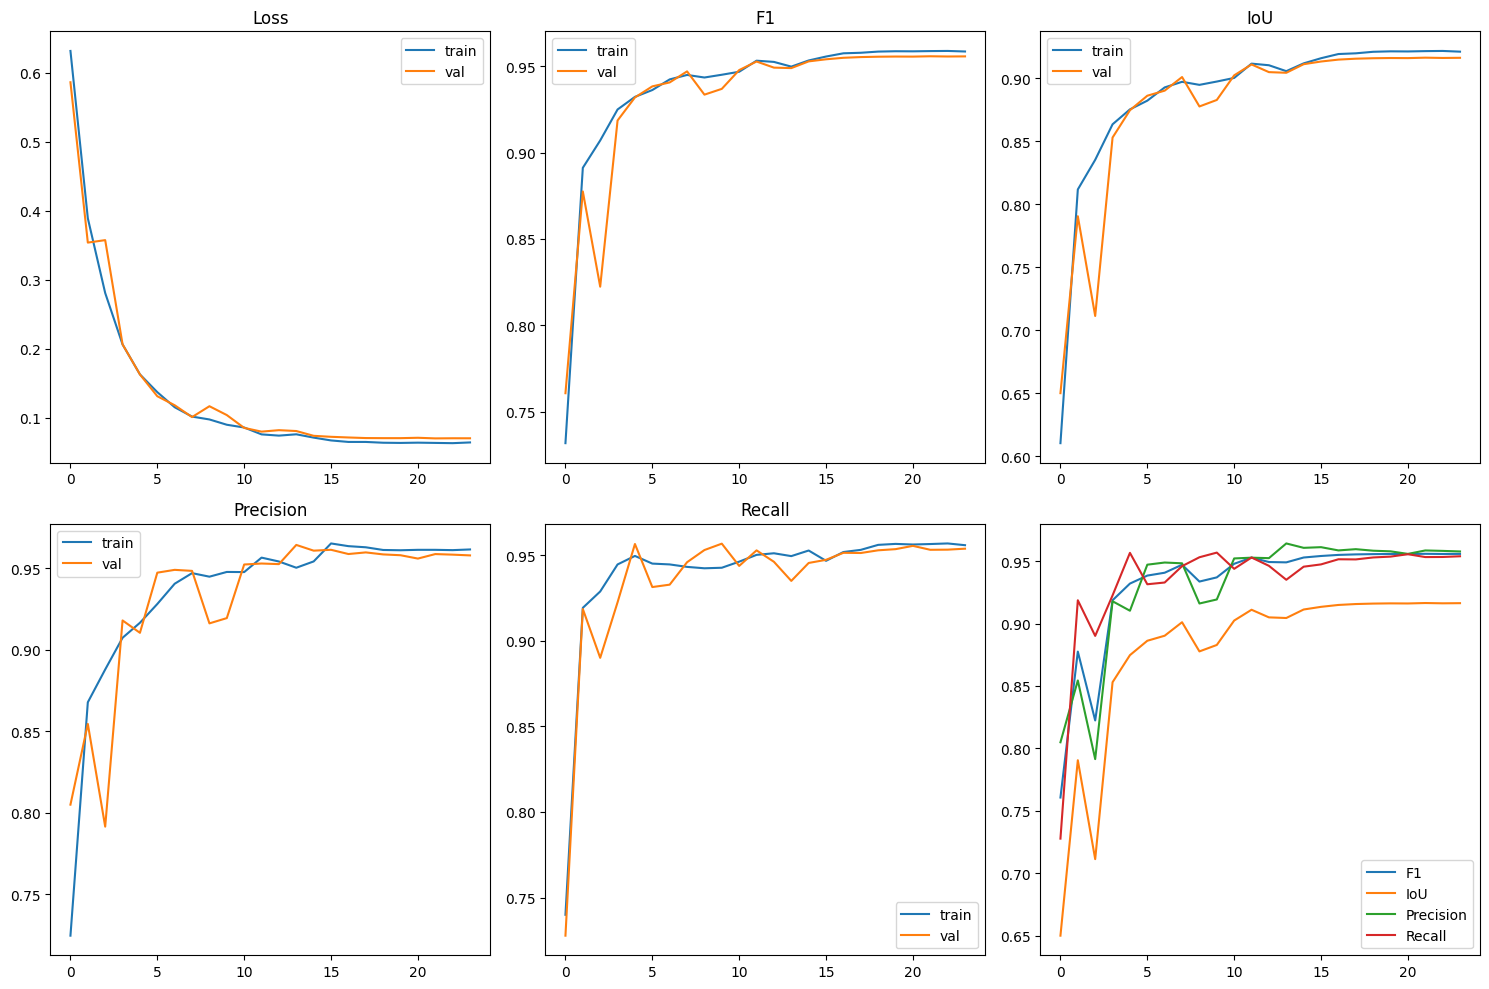

Финальные значения:
Train Loss: 0.0640
Val Loss: 0.0701
Val F1: 0.9558
Val IoU: 0.9163
Val Precision: 0.9577
Val Recall: 0.9539


In [168]:
draw_graphs("logs_task2/unet/version_0/metrics.csv")

In [169]:
from PIL import Image

def draw_images(pred_dir):
    epoch_files = list(pred_dir.glob("epoch_*.png"))
    total_epochs = len(epoch_files)
    epochs_to_show = [0, total_epochs // 3, total_epochs * 2 // 3, total_epochs - 1]

    for epoch in epochs_to_show:
        img_path = pred_dir / f"epoch_{epoch:03d}.png"
        img = Image.open(img_path)
        plt.figure(figsize=(12, 6))
        plt.imshow(img)
        plt.axis("off")
        plt.show()

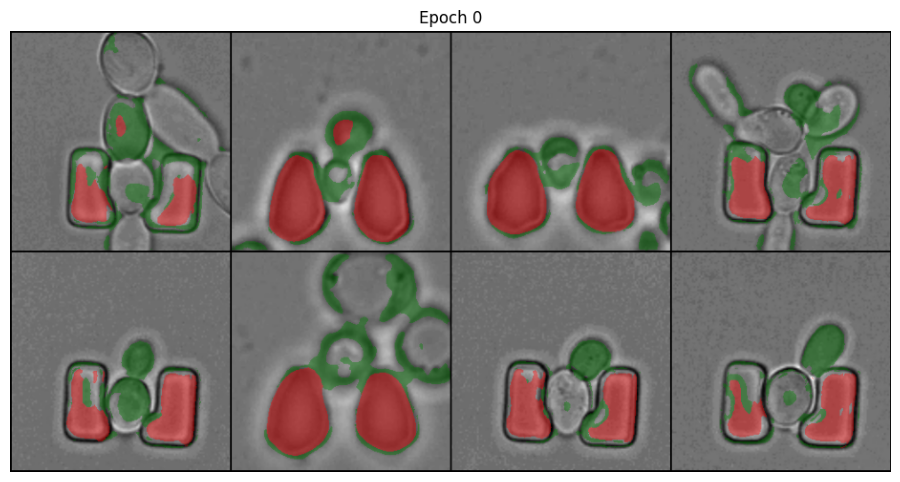

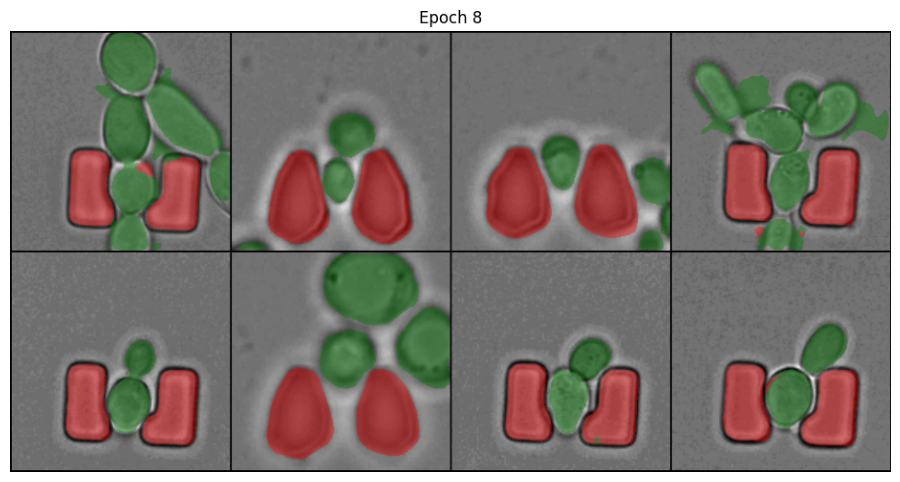

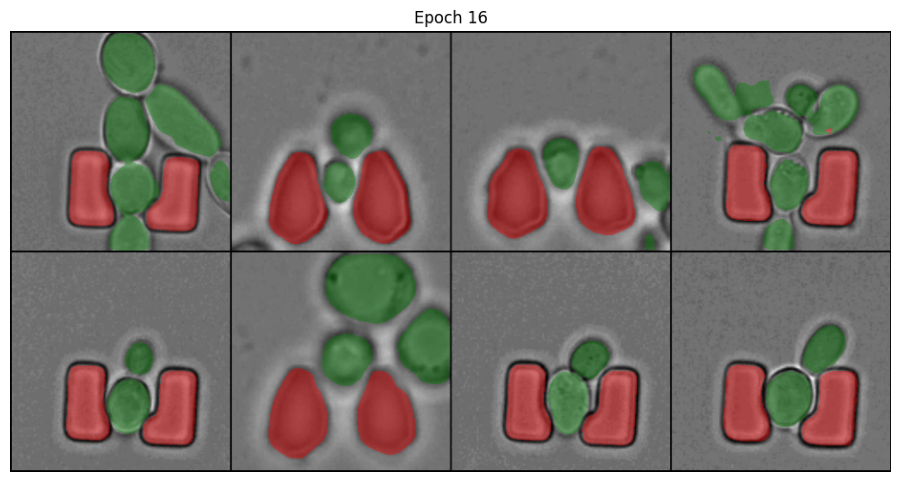

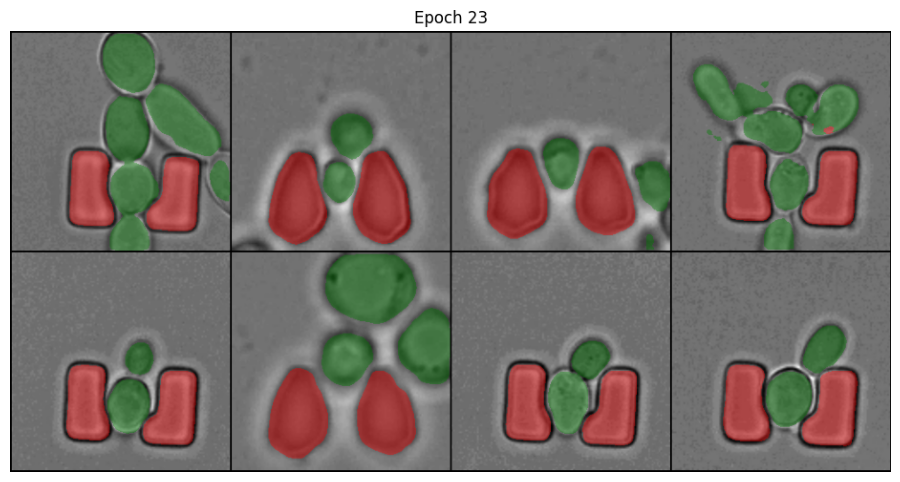

In [170]:
draw_images(Path("predictions_task2"))

### Задание 3 (3 балла). Выбор другой функции ошибки

Полезная ссылка:
https://www.jeremyjordan.me/semantic-segmentation/#loss

Повторите эксперимент из задания 2, но попробуйте модифицировать функцию ошибки:
- (2 балла) учитывайте пиксели на границе объектов с большим весом, как предлагается в статье [U-Net](https://arxiv.org/abs/1505.04597)
- (1 балл) используйте soft Dice loss

Опишите свои наблюдения, что изменилось? Обратите внимание на скорость обучения, визуальные артефакты предсказаний, динамику метрик.


In [204]:
class BorderUNetLoss(nn.Module):
    def __init__(
        self,
        num_classes: int,
    ):
        super().__init__()
        self.num_classes = num_classes
        self.border_weight = 4.0
        self.filter = torch.tensor([[[
            [ 0, -1,  0],
            [-1,  4, -1],
            [ 0, -1,  0],
        ]]], dtype=torch.float)

    def compute_border_weights(self, masks: Tensor) -> Tensor:
        batch_size, height, width = masks.shape
        
        border_weights = torch.ones_like(masks, dtype=torch.float)
        
        for i in range(batch_size):
            mask = masks[i].unsqueeze(0).unsqueeze(0).float()
            
            if self.filter.device != mask.device:
                self.filter = self.filter.to(mask.device)
            
            borders = F.conv2d(mask, self.filter, padding=1)
            borders = torch.abs(borders) > 0.4
            border_weights[i][borders.squeeze()] = self.border_weight
        
        return border_weights
    
    def forward(self, pred: Tensor, target: Tensor) -> Tensor:
        border_weights = self.compute_border_weights(target)
        
        cross_entr_loss = F.cross_entropy(pred, target, reduction='none')
        weighted_loss = cross_entr_loss * border_weights
        
        return weighted_loss.mean()

In [205]:
class BorderUNetLit(L.LightningModule):
    def __init__(self, model: nn.Module, learning_rate: float, num_classes: int) -> None:
        super().__init__()
        self.save_hyperparameters(ignore=['model'])
        self.model = model

        self.learning_rate = learning_rate
        self.num_classes = num_classes

        self.train_metrics = create_metrics(num_classes=self.num_classes, prefix="train_")
        self.val_metrics = create_metrics(num_classes=self.num_classes, prefix="val_")

        self.func = BorderUNetLoss(num_classes)

    def training_step(
        self, batch: tuple[Tensor, Tensor], batch_idx: int
    ) -> STEP_OUTPUT:

        x, y = batch
        y_hat = self.model(x)
        loss = self.func(y_hat, y)
        y_pred = torch.argmax(y_hat, dim=1)
        self.log("train_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        self.train_metrics.update(y_pred, y)
        self.log_dict(self.train_metrics, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def validation_step(
        self, batch: tuple[Tensor, Tensor], batch_idx: int
    ) -> STEP_OUTPUT | None:
        x, y = batch
        y_hat = self.model(x)
        loss = self.func(y_hat, y)
        y_pred = torch.argmax(y_hat, dim=1)
        self.log("val_loss", loss, on_epoch=True, on_step=False, prog_bar=True)
        self.val_metrics.update(y_pred, y)
        self.log_dict(self.val_metrics, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def configure_optimizers(self) -> dict[str, Any]:
        optimizer = torch.optim.Adam(self.model.parameters(), lr=self.learning_rate)
        return {
            "optimizer": optimizer,
            "lr_scheduler": torch.optim.lr_scheduler.MultiStepLR(
                optimizer,
                milestones=[15, 20, 15],
                gamma=0.1,
            ),

        }

In [206]:
border_callbacks = [
    ModelCheckpoint(
        filename="{epoch}-{val_MulticlassJaccardIndex:.4f}",
        monitor="val_MulticlassJaccardIndex",
        mode="max",
        save_top_k=2,
        save_last=True,
    ),
    EarlyStopping(
        monitor="val_MulticlassJaccardIndex",
        mode="max",
        patience=5,
        min_delta=0.001
    ),
    SavePredictionsCallback(datamodule, output_dir="predictions_task3_1"),
]

In [207]:
border_logger = CSVLogger(save_dir="logs_task3_1", name="unet")
border_model = UNet(n_channels=1, n_classes=3, channel_sizes=[16, 32, 64, 128], bilinear=True)

border_model_lit = BorderUNetLit(model=border_model, learning_rate=1e-3, num_classes=3)

border_trainer = Trainer(
    max_epochs=50,
    logger=border_logger,
    callbacks=border_callbacks,
    accelerator="auto",
)

border_trainer.fit(border_model_lit, datamodule=datamodule)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name          | Type             | Params | Mode 
-----------------------------------------------------------
0 | model         | UNet             | 268 K  | train
1 | train_metrics | MetricCollection | 0      | train
2 | val_metrics   | MetricCollection | 0      | train
3 | func          | BorderUNetLoss   | 0      | train
-----------------------------------------------------------
268 K     Trainable params
0         Non-trainable params
268 K     Total params
1.074     Total estimated model params size (MB)
86        Modules in train mode
0         Modules in eval mode


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/home/vladimir/dl_hw/.venv/lib/python3.13/site-packages/pytorch_lightning/loops/fit_loop.py:310: The number of training batches (37) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

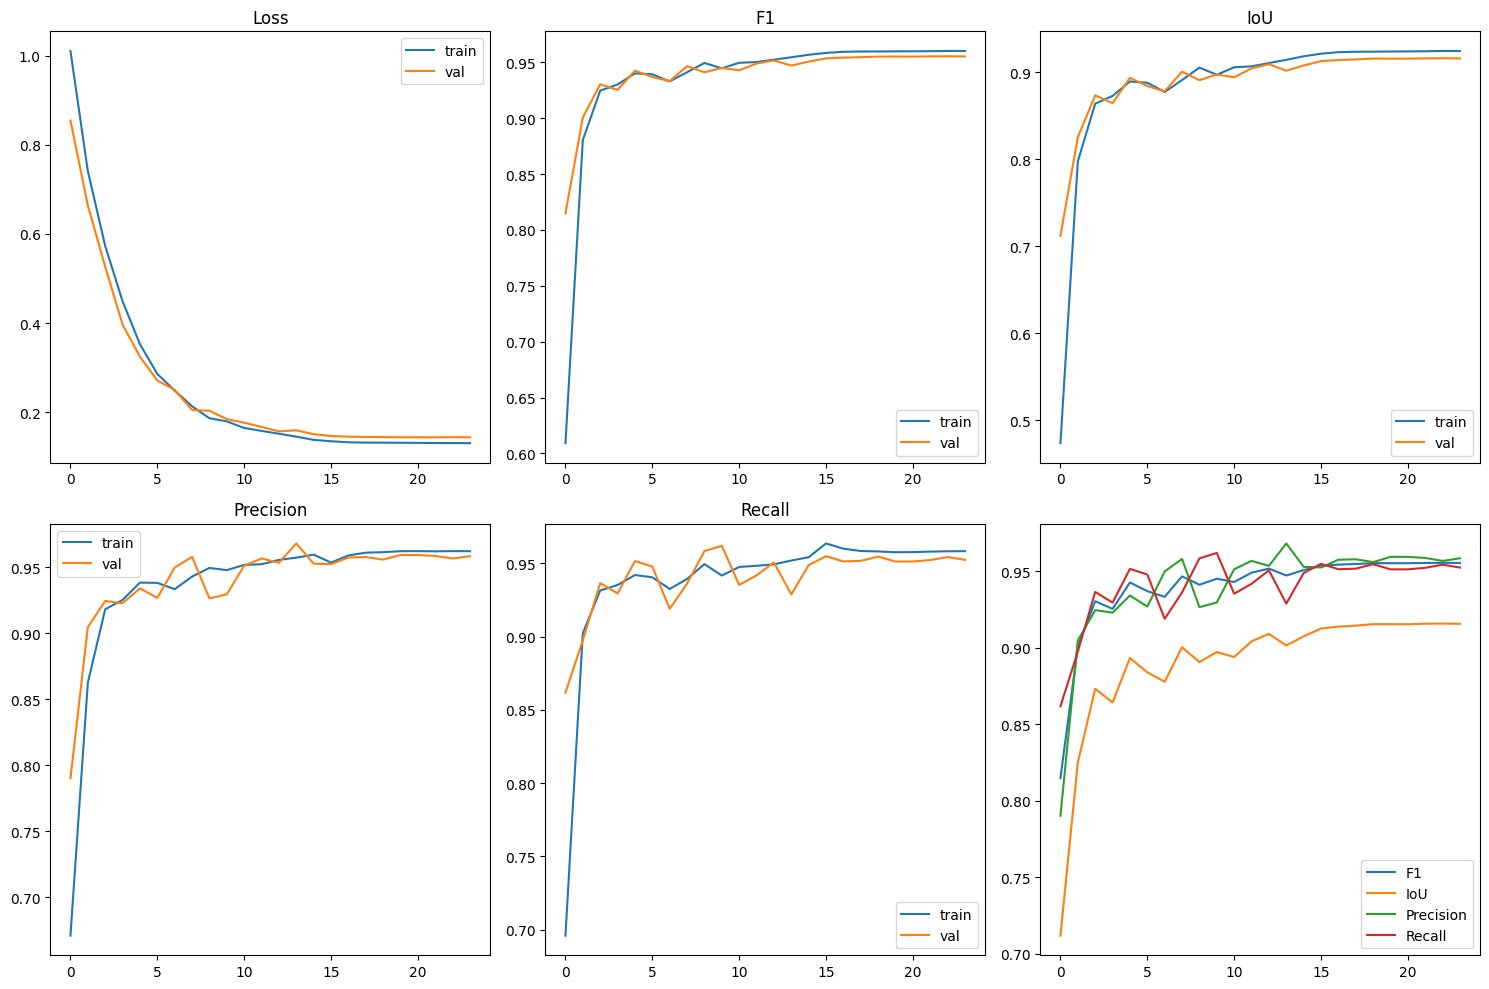

Финальные значения:
Train Loss: 0.1303
Val Loss: 0.1434
Val F1: 0.9554
Val IoU: 0.9157
Val Precision: 0.9585
Val Recall: 0.9524


In [208]:
draw_graphs("logs_task3_1/unet/version_0/metrics.csv")

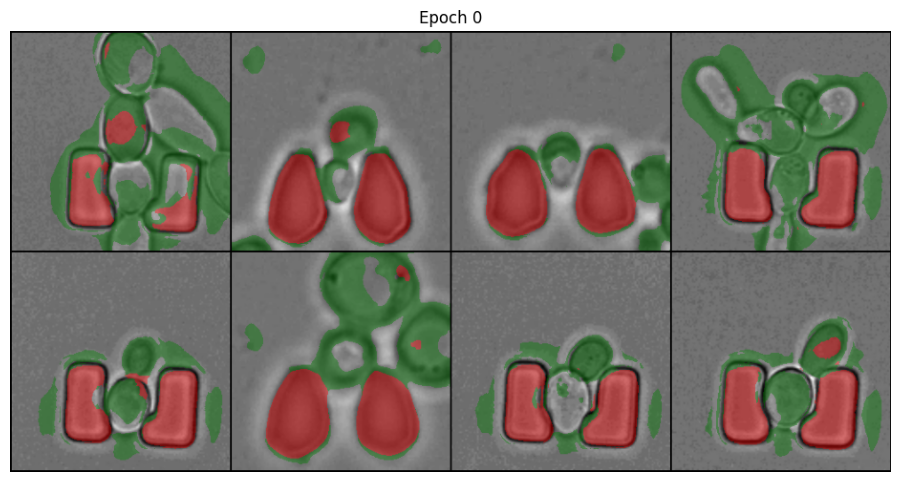

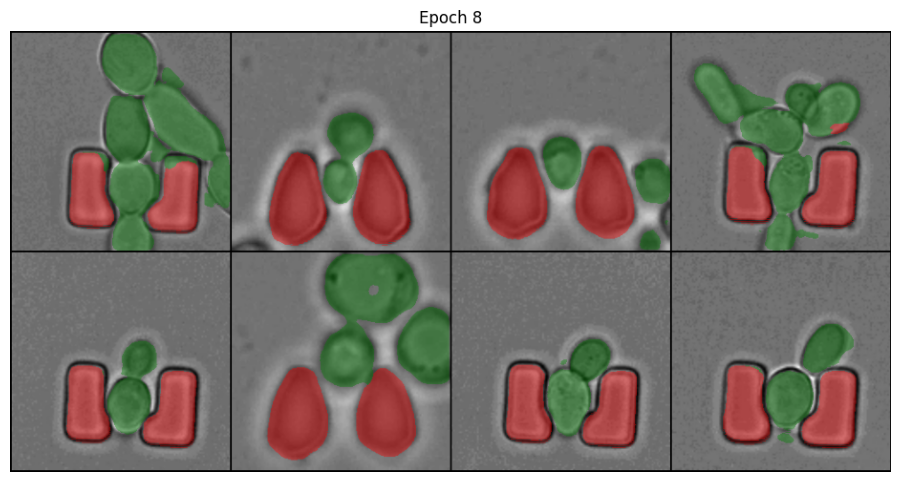

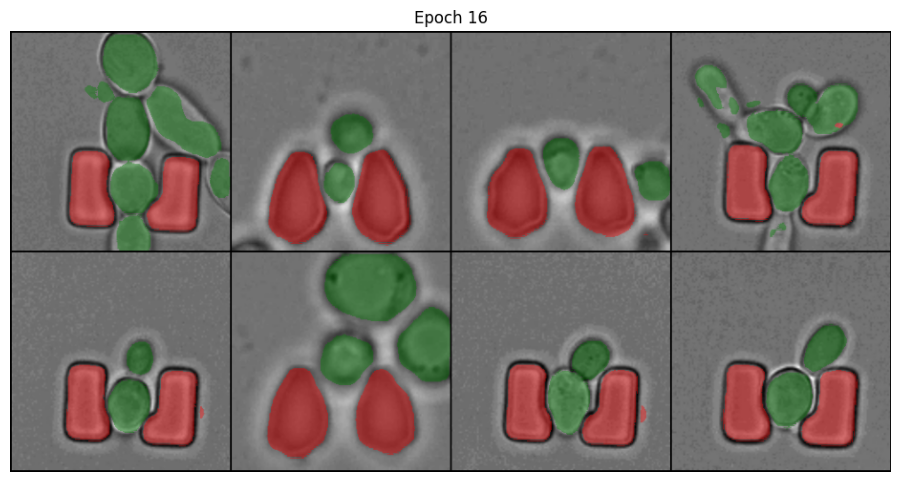

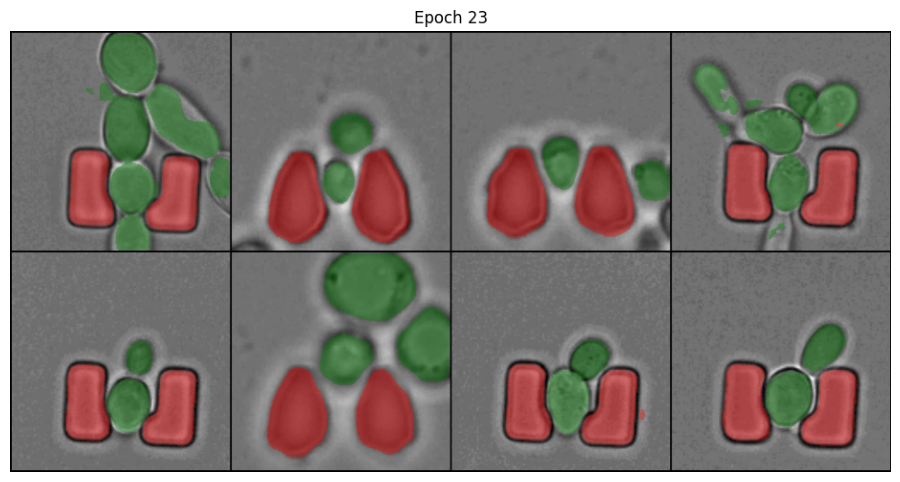

In [209]:
draw_images(Path("predictions_task3_1"))

Раскраска клеток начала меньше слипаться друг с другом, больше видны четкие границы между объектами. Значения метрик практически не изменились

In [177]:
class SoftDiceUNet(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.num_classes = num_classes
        self.eps = 1e-6

    def forward(self, pred: Tensor, target: Tensor) -> Tensor:
        pred_softmax = F.softmax(pred, dim=1)
        
        dice_loss = 0.0

        for class_id in range(self.num_classes):
            pred_class = pred_softmax[:, class_id]
            target_class = (target == class_id).float()
            
            intersection = (pred_class * target_class).sum(dim=(1, 2))
            union = pred_class.sum(dim=(1, 2)) + target_class.sum(dim=(1, 2))
            
            dice_coeff = (2.0 * intersection + self.eps) / (union + self.eps)
            dice_loss += (1.0 - dice_coeff).mean()
        
        return dice_loss / self.num_classes

In [178]:
class DiceUNet(nn.Module):
    def __init__(self, num_classes: int):
        super().__init__()
        self.num_classes = num_classes
        self.dice_weight = 1.0

        self.dice_loss = SoftDiceUNet(num_classes)

    def forward(self, pred: Tensor, target: Tensor) -> Tensor:
        dice_loss = self.dice_loss(pred, target)
        
        total_loss = self.dice_weight * dice_loss
        
        return total_loss

In [179]:
class DiceUNetLit(L.LightningModule):
    def __init__(self, model: nn.Module, learning_rate: float, num_classes: int) -> None:
        super().__init__()
        self.save_hyperparameters(ignore=['model'])
        self.model = model

        self.learning_rate = learning_rate
        self.num_classes = num_classes

        self.train_metrics = create_metrics(num_classes=self.num_classes, prefix="train_")
        self.val_metrics = create_metrics(num_classes=self.num_classes, prefix="val_")

        self.func = DiceUNet(num_classes)

    def training_step(
        self, batch: tuple[Tensor, Tensor], batch_idx: int
    ) -> STEP_OUTPUT:

        x, y = batch
        y_hat = self.model(x)
        loss = self.func(y_hat, y)
        y_pred = torch.argmax(y_hat, dim=1)
        self.log("train_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        self.train_metrics.update(y_pred, y)
        self.log_dict(self.train_metrics, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def validation_step(
        self, batch: tuple[Tensor, Tensor], batch_idx: int
    ) -> STEP_OUTPUT | None:
        x, y = batch
        y_hat = self.model(x)
        loss = self.func(y_hat, y)
        y_pred = torch.argmax(y_hat, dim=1)
        self.log("val_loss", loss, on_epoch=True, on_step=False, prog_bar=True)
        self.val_metrics.update(y_pred, y)
        self.log_dict(self.val_metrics, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def configure_optimizers(self) -> dict[str, Any]:
        optimizer = torch.optim.Adam(self.model.parameters(), lr=self.learning_rate)
        return {
            "optimizer": optimizer,
            "lr_scheduler": torch.optim.lr_scheduler.MultiStepLR(
                optimizer,
                milestones=[15, 20, 15],
                gamma=0.1,
            ),

        }

In [180]:
dice_callbacks = [
    ModelCheckpoint(
        filename="{epoch}-{val_MulticlassJaccardIndex:.4f}",
        monitor="val_MulticlassJaccardIndex",
        mode="max",
        save_top_k=2,
        save_last=True,
    ),
    EarlyStopping(
        monitor="val_MulticlassJaccardIndex",
        mode="max",
        patience=5,
        min_delta=0.001
    ),
    SavePredictionsCallback(datamodule, output_dir="predictions_task3_2"),
]

In [181]:
dice_logger = CSVLogger(save_dir="logs_task3_2", name="unet")
dice_model = UNet(n_channels=1, n_classes=3, channel_sizes=[16, 32, 64, 128], bilinear=True)

dice_model_lit = DiceUNetLit(model=dice_model, learning_rate=1e-3, num_classes=3)

dice_trainer = Trainer(
    max_epochs=50,
    logger=dice_logger,
    callbacks=dice_callbacks,
    accelerator="auto",
)

dice_trainer.fit(dice_model_lit, datamodule=datamodule)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name          | Type             | Params | Mode 
-----------------------------------------------------------
0 | model         | UNet             | 268 K  | train
1 | train_metrics | MetricCollection | 0      | train
2 | val_metrics   | MetricCollection | 0      | train
3 | func          | DiceUNet         | 0      | train
-----------------------------------------------------------
268 K     Trainable params
0         Non-trainable params
268 K     Total params
1.074     Total estimated model params size (MB)
87        Modules in train mode
0         Modules in eval mode


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/home/vladimir/dl_hw/.venv/lib/python3.13/site-packages/pytorch_lightning/loops/fit_loop.py:310: The number of training batches (37) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

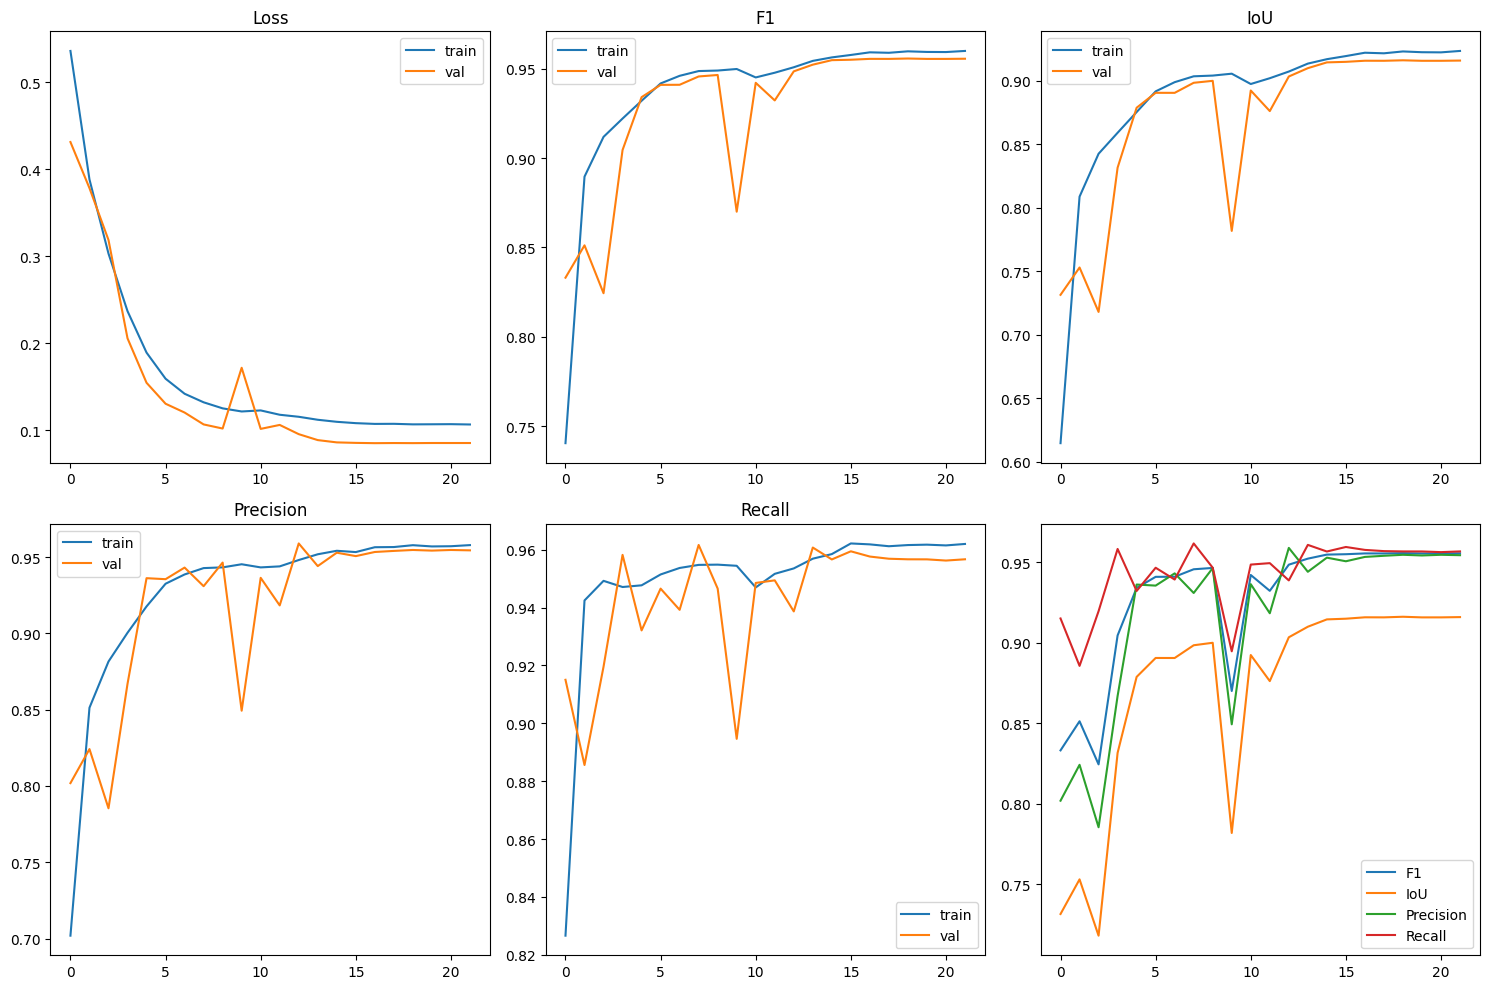

Финальные значения:
Train Loss: 0.1067
Val Loss: 0.0855
Val F1: 0.9555
Val IoU: 0.9159
Val Precision: 0.9544
Val Recall: 0.9567


In [182]:
draw_graphs("logs_task3_2/unet/version_0/metrics.csv")

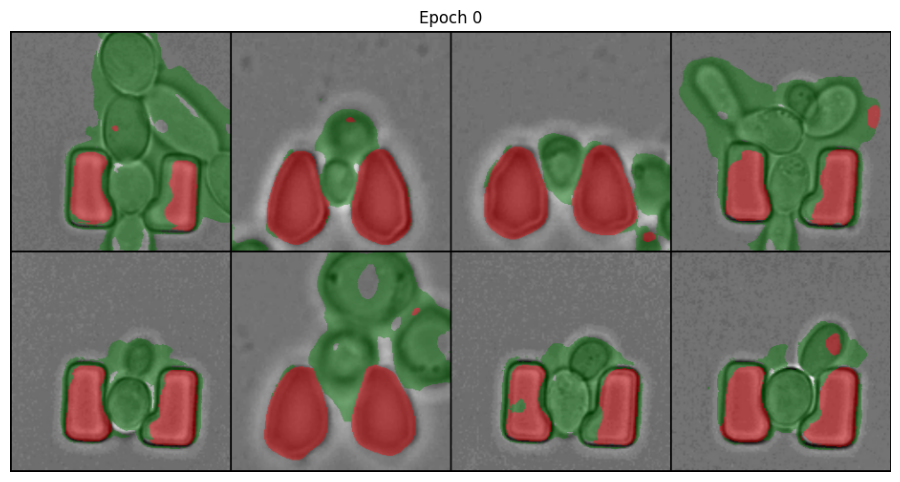

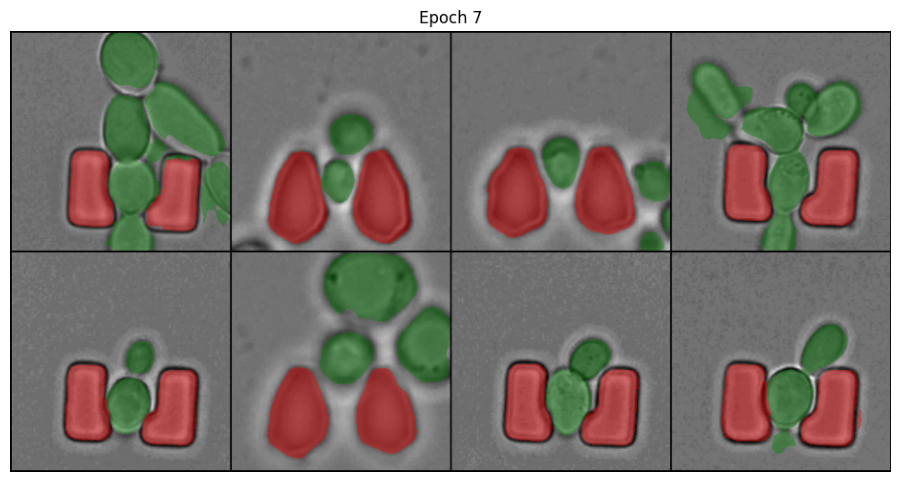

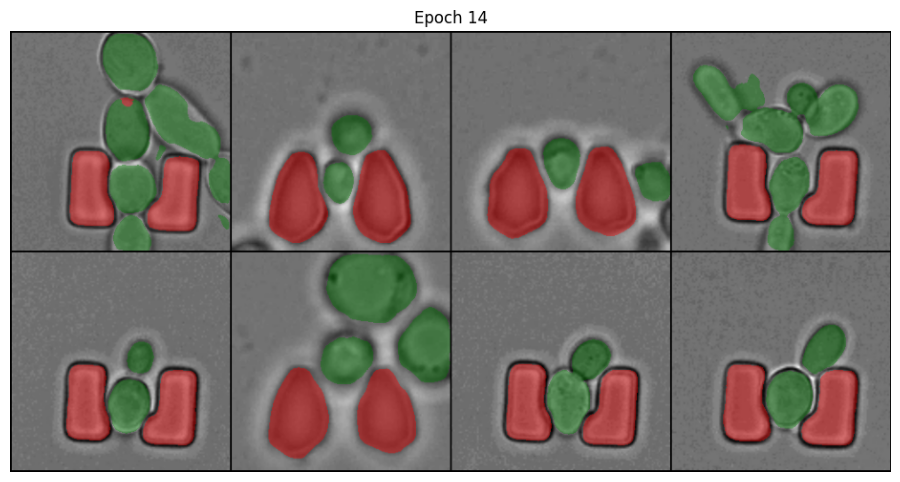

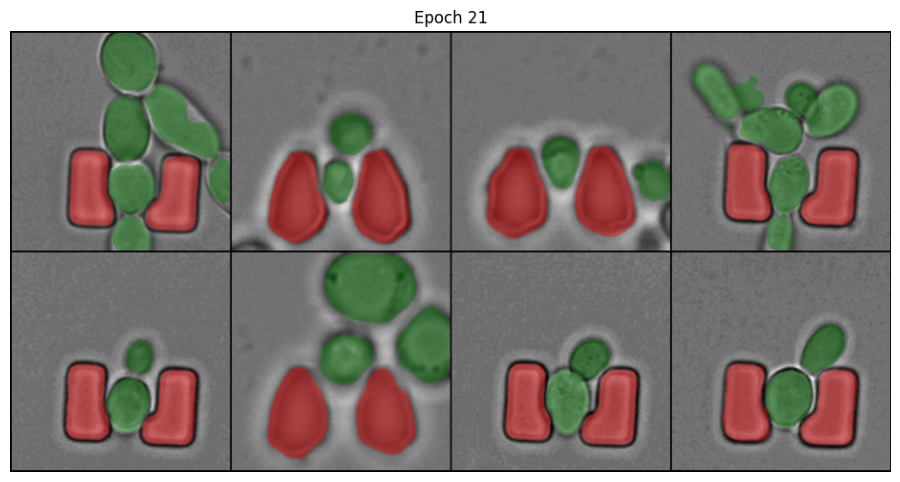

In [183]:
draw_images(Path("predictions_task3_2"))

Видно, что метрики достигают высоких значений на более ранних эпохах, а лосс наоборот падает быстрее. Так же раскраска клеток почти не имеет разрывов внутри объектов, модель неплохо замечает маленькие объекты, но иногда вылезает за границы клетки.

### Задание 4 (3 балла). Модификация архитектуры

Ваша задача - извлечь максимальную точность из модели, в которой будет не более 50k параметров. Для этого внесите правки в архитектуру модели.

В частности, попробуйте заменить в блоке `Down` комбинацию conv+maxpool на dilated conv с увеличенным stride (`nn.Conv2d(..., dilation=2, stride=2)`). В остальном - полная свобода творчества, можете перерабатывать архитектуру как угодно.

Ожидается, что просадка в точности по всем метрикам не будет превышать 10%; в частности, accuracy 90% вполне достижима.

Как обычно, запустите эксперимент (или несколько) с выводом всех графиков и картинок.

In [184]:
class SmallDoubleConv(nn.Module):

    def __init__(
        self, in_channels: int, out_channels: int, mid_channels: int | None = None
    ) -> None:
        super().__init__()
        if not mid_channels:
            mid_channels = out_channels
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, mid_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(mid_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(mid_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x: Tensor) -> Tensor:
        return self.double_conv(x)

In [185]:
class SmallDown(nn.Module):

    def __init__(self, in_channels: int, out_channels: int) -> None:
        super().__init__()
        self.small_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=2, dilation=2, stride=2, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x: Tensor) -> Tensor:
        return self.small_conv(x)

In [186]:
def create_small_downscaler(channel_sizes: list[int], bilinear: bool = False) -> nn.ModuleList:
    modules = []
    for i in range(len(channel_sizes) - 1):
        in_channels = channel_sizes[i]
        out_channels = channel_sizes[i + 1]
        is_last_module = i == len(channel_sizes) - 2
        dfactor = 2 if bilinear and is_last_module else 1
        modules.append(SmallDown(in_channels, out_channels // dfactor))

    return nn.ModuleList(modules)

In [187]:
class SmallUp(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, bilinear: bool = True) -> None:
        super().__init__()

        if bilinear:
            self.up = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=True)
            self.conv = DoubleConv(in_channels, out_channels, in_channels // 2)
        else:
            self.up = nn.ConvTranspose2d(in_channels, in_channels // 2, kernel_size=2, stride=2)
            self.conv = DoubleConv(in_channels, out_channels)

    def forward(self, x_prev: Tensor, x_skip: Tensor) -> Tensor:
        x_prev = self.up(x_prev)
        x = torch.cat([x_skip, x_prev], dim=1)
        return self.conv(x)

In [188]:
def create_small_upscaler(channel_sizes: list[int], bilinear: bool = False) -> nn.ModuleList:
    modules = []
    for i in range(len(channel_sizes) - 1):
        in_channels = channel_sizes[i]
        out_channels = channel_sizes[i + 1]
        is_last_module = i == len(channel_sizes) - 2
        dfactor = 2 if bilinear and not is_last_module else 1
        modules.append(Up(in_channels, out_channels // dfactor, bilinear=bilinear))

    return nn.ModuleList(modules)

In [189]:
class SmallUNet(nn.Module):
    def __init__(
        self,
        n_channels: int,
        n_classes: int,
        channel_sizes: list[int],
        bilinear: bool = False,
    ):
        super().__init__()
        self.in_conv = DoubleConv(in_channels=n_channels, out_channels=channel_sizes[0])
        self.downscaler = create_small_downscaler(channel_sizes, bilinear)
        self.upscaler = create_small_upscaler(channel_sizes[::-1], bilinear)
        self.head = nn.Conv2d(channel_sizes[0], n_classes, kernel_size=1)

    def forward(self, x: Tensor) -> Tensor:
        x = self.in_conv(x)

        xs = []
        for conv in self.downscaler:
            xs.append(x)
            x = conv(x)

        xs.reverse()
        for conv, act in zip(self.upscaler, xs):
            x = conv(x, act)

        logits = self.head(x)
        return logits

In [190]:
class SmallUNetLit(L.LightningModule):
    def __init__(self, model: nn.Module, learning_rate: float, num_classes: int) -> None:
        super().__init__()
        self.save_hyperparameters(ignore=['model'])
        self.model = model

        self.learning_rate = learning_rate
        self.num_classes = num_classes

        self.train_metrics = create_metrics(num_classes=self.num_classes, prefix="train_")
        self.val_metrics = create_metrics(num_classes=self.num_classes, prefix="val_")

    def training_step(
        self, batch: tuple[Tensor, Tensor], batch_idx: int
    ) -> STEP_OUTPUT:

        x, y = batch
        y_hat = self.model(x)
        loss = F.cross_entropy(y_hat, y)
        y_pred = torch.argmax(y_hat, dim=1)
        self.log("train_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        self.train_metrics.update(y_pred, y)
        self.log_dict(self.train_metrics, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def validation_step(
        self, batch: tuple[Tensor, Tensor], batch_idx: int
    ) -> STEP_OUTPUT | None:
        x, y = batch
        y_hat = self.model(x)
        loss = F.cross_entropy(y_hat, y)
        y_pred = torch.argmax(y_hat, dim=1)
        self.log("val_loss", loss, on_epoch=True, on_step=False, prog_bar=True)
        self.val_metrics.update(y_pred, y)
        self.log_dict(self.val_metrics, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def configure_optimizers(self) -> dict[str, Any]:
        optimizer = torch.optim.Adam(self.model.parameters(), lr=self.learning_rate)
        return {
            "optimizer": optimizer,
            "lr_scheduler": torch.optim.lr_scheduler.MultiStepLR(
                optimizer,
                milestones=[15, 20, 15],
                gamma=0.1,
            ),

        }

In [210]:
import random
import matplotlib.pyplot as plt

dataset_dir = Path("yeast_cell_in_microstructures_dataset")
train_dir = dataset_dir / "train"
datamodule = UNetDataModule(datadir=dataset_dir, batch_size=8, num_workers=15)
        
small_callbacks = [
    ModelCheckpoint(
        filename="{epoch}-{val_MulticlassJaccardIndex:.4f}",
        monitor="val_MulticlassJaccardIndex",
        mode="max",
        save_top_k=2,
        save_last=True,
    ),
    EarlyStopping(
        monitor="val_MulticlassJaccardIndex",
        mode="max",
        patience=5,
        min_delta=0.001
    ),
    SavePredictionsCallback(datamodule, output_dir="predictions_task4"),
]

In [211]:
small_logger = CSVLogger(save_dir="logs_task4", name="unet")
small_model = SmallUNet(n_channels=1, n_classes=3, channel_sizes=[8, 16, 32, 64], bilinear=True)

small_model_lit = SmallUNetLit(model=small_model, learning_rate=1e-3, num_classes=3)

small_trainer = Trainer(
    max_epochs=50,
    logger=small_logger,
    callbacks=small_callbacks,
    accelerator="auto",
)

small_trainer.fit(small_model_lit, datamodule=datamodule)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name          | Type             | Params | Mode 
-----------------------------------------------------------
0 | model         | SmallUNet        | 46.5 K | train
1 | train_metrics | MetricCollection | 0      | train
2 | val_metrics   | MetricCollection | 0      | train
-----------------------------------------------------------
46.5 K    Trainable params
0         Non-trainable params
46.5 K    Total params
0.186     Total estimated model params size (MB)
67        Modules in train mode
0         Modules in eval mode


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/home/vladimir/dl_hw/.venv/lib/python3.13/site-packages/pytorch_lightning/loops/fit_loop.py:310: The number of training batches (37) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

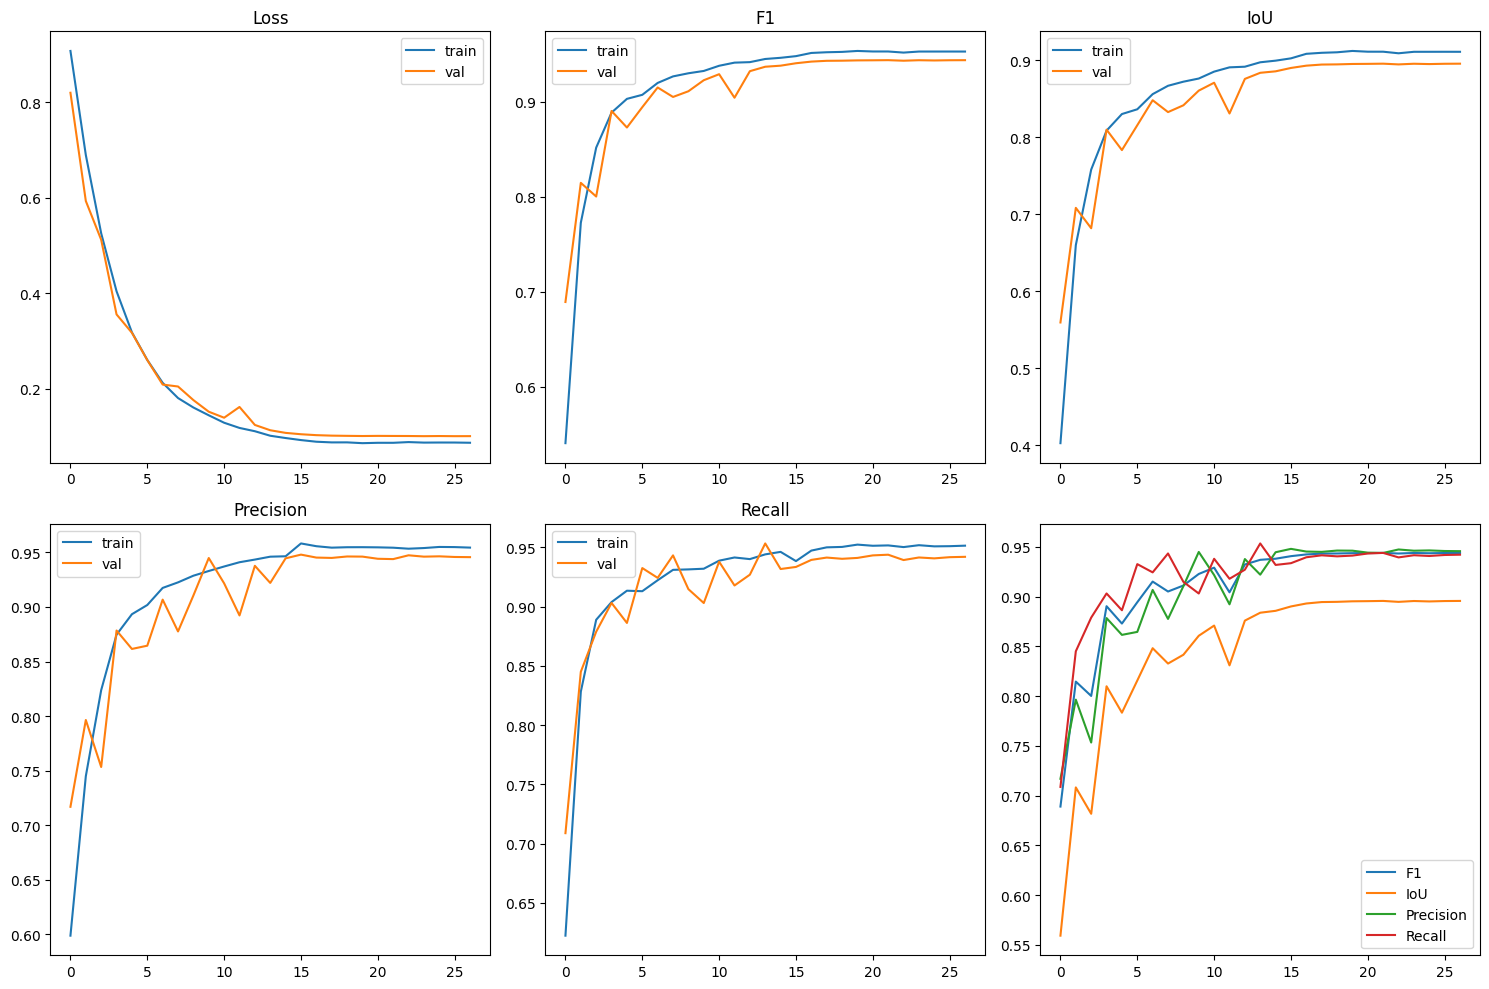

Финальные значения:
Train Loss: 0.0868
Val Loss: 0.1007
Val F1: 0.9438
Val IoU: 0.8956
Val Precision: 0.9456
Val Recall: 0.9420


In [212]:
draw_graphs("logs_task4/unet/version_0/metrics.csv")

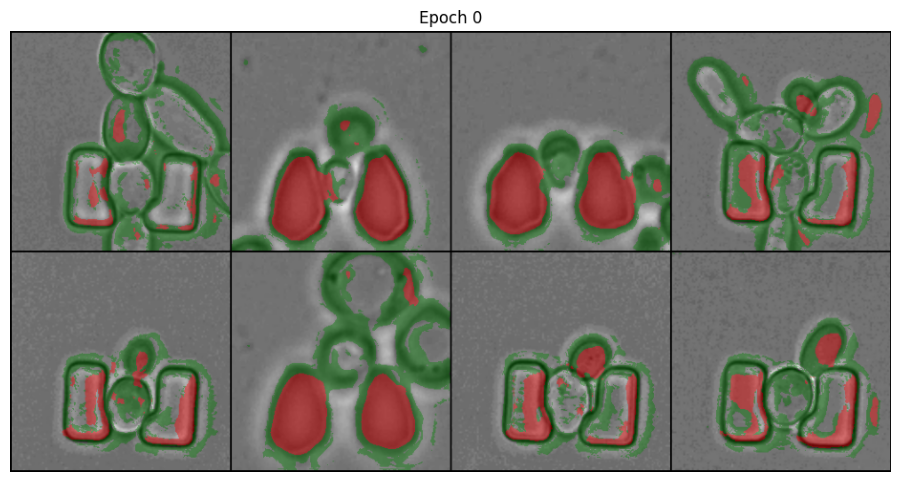

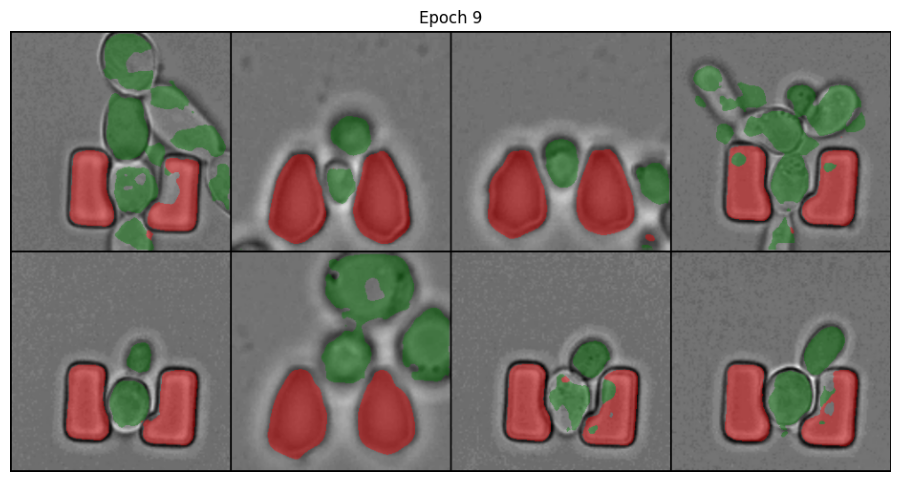

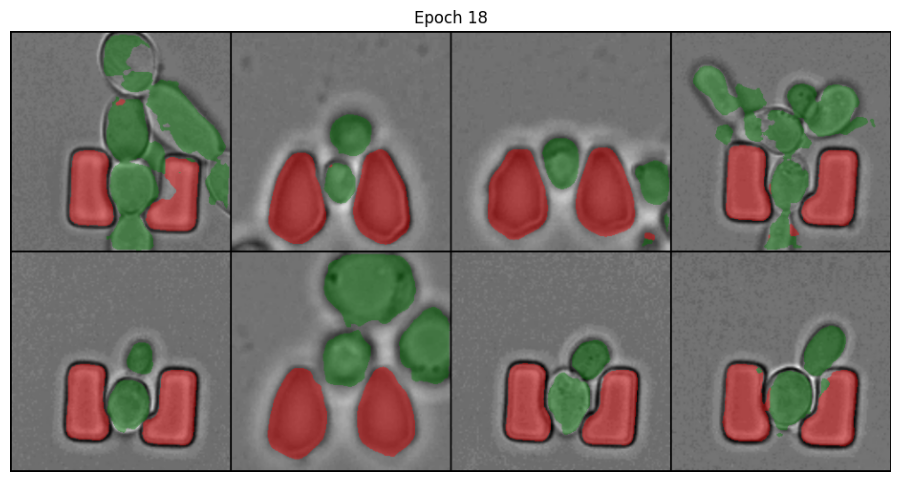

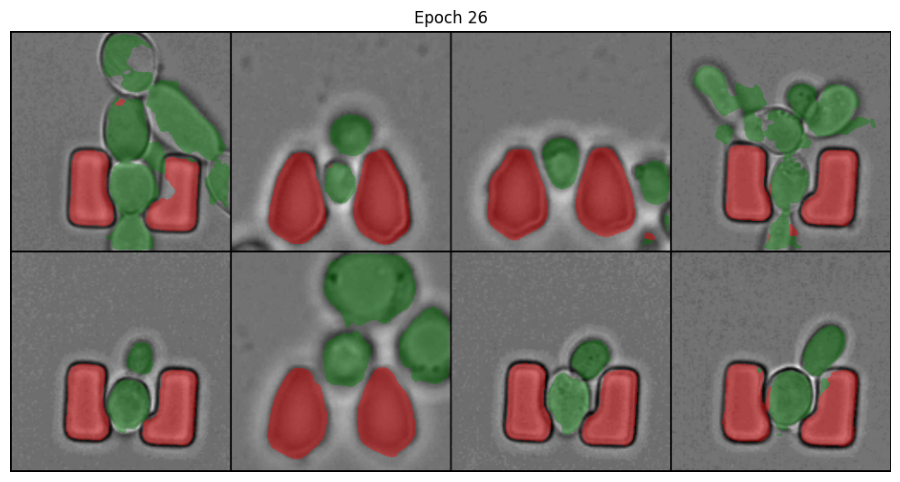

In [213]:
draw_images(Path("predictions_task4"))

Обучение длилось чуть больше эпох, значения метрик немного упали, но в общем и целом все неплохо выглядит.